# Karpowership fleet analysis: a walkthrough

This notebook goes through the analysis step by step, using the functions of the
`karpowership` package (the same functions the web app uses, nothing is copied here).

1. Load and clean the real records
2. Generate the full dataset (2024 – November 2026)
3. Calculate the metrics
4. Reshape the data by month
5. Visualise the fleet
6. Find downtime and efficiency alerts
7. Statistics with numpy and scipy
8. Conclusions

In [1]:
import sys
sys.path.insert(0, "..")  # so that the karpowership package (one folder up) can be imported

from karpowership import alerts, analysis, plots
from karpowership.calculations import add_daily_metrics, summarize, summarize_by
from karpowership.data import ORIGINAL_FILE, add_month, load_records, monthly_table, one_row_per_day
from karpowership.simulation import build_dataset

## 1. Load and clean the real records

The original Excel file has one row per ship and day for January – March 2024.
`load_records` fixes the types and adds a `status` column: rows with missing
values get the status `no_data`.

In [2]:
original = load_records(ORIGINAL_FILE)
original.head()

,ship_name,date,production_mwh,fuel_consumption_ton,status,event_note,source
0,Doğan Bey,2024-01-01,207.0,39.5,operating,,original
1,Doğan Bey,2024-01-02,389.5,84.0,operating,,original
2,Doğan Bey,2024-01-03,208.3,39.3,operating,,original
3,Doğan Bey,2024-01-04,NaN,NaN,no_data,,original
4,Doğan Bey,2024-01-05,352.6,66.6,operating,,original


In [3]:
print("Rows:", len(original))
print("Ships:", sorted(original["ship_name"].unique()))
print("Dates:", original["date"].min().date(), "to", original["date"].max().date())
print("Rows with missing values:", original["production_mwh"].isna().sum())
print("Ship-days with two records:", original.duplicated(["ship_name", "date"]).sum())

Rows: 291
Ships: ['Doğan Bey', 'Kaya Bey', 'Rauf Bey']
Dates: 2024-01-01 to 2024-03-30
Rows with missing values: 24
Ship-days with two records: 21


Some ship-days have two records. `one_row_per_day` adds them up so that every
ship has exactly one row per day:

In [4]:
one_row_per_day(original).head()

,ship_name,date,production_mwh,fuel_consumption_ton,status,event_note,n_records
0,Doğan Bey,2024-01-01,207.0,39.5,operating,,1
1,Doğan Bey,2024-01-02,389.5,84.0,operating,,1
2,Doğan Bey,2024-01-03,208.3,39.3,operating,,1
3,Doğan Bey,2024-01-04,NaN,NaN,no_data,,1
4,Doğan Bey,2024-01-05,352.6,66.6,operating,,1


## 2. Generate the full dataset

The real data only covers three months. `build_dataset` keeps it and adds realistic
mock data until 30 November 2026 (4 more ships, seasonal demand, maintenance,
missing reports) with two scenarios:

- **Rauf Bey** breaks down from 1 July to 14 August 2024 (45 days),
- **Nilüfer Sultan** waits idle offshore from 29 January to 17 March 2026 (48 days):
  it produces nothing and burns only a little fuel for heating and maintenance.

In [5]:
records = build_dataset()
print(len(records), "records from", records["date"].min().date(), "to", records["date"].max().date())
records["status"].value_counts()

7341 records from 2024-01-01 to 2026-11-30


status
operating      6663
no_data         250
maintenance     225
ramp_up         110
idle             48
outage           45
Name: count, dtype: int64

In [6]:
nilufer = records[(records["ship_name"] == "Nilüfer Sultan")
                  & records["date"].between("2026-01-26", "2026-03-20")]
nilufer.iloc[[0, 1, 2, 3, 4, 5, -6, -5, -4, -3, -2, -1]][["date", "production_mwh", "fuel_consumption_ton", "status"]]

,date,production_mwh,fuel_consumption_ton,status
4896,2026-01-26,340.1,66.4,operating
4897,2026-01-27,359.8,70.5,operating
4898,2026-01-28,440.7,85.8,operating
4899,2026-01-29,0.0,0.6,idle
4900,2026-01-30,0.0,1.0,idle
4901,2026-01-31,0.0,0.8,idle
4944,2026-03-15,0.0,1.0,idle
4945,2026-03-16,0.0,0.8,idle
4946,2026-03-17,0.0,0.7,idle
4947,2026-03-18,85.6,17.0,ramp_up


## 3. Calculate the metrics

`add_daily_metrics` merges the ship information (capacity, site) and adds the
daily metrics: efficiency (MWh per tonne), capacity factor, fuel cost, revenue,
profit and CO₂. `summarize` turns any group of days into totals and ratios.

In [7]:
daily = add_daily_metrics(one_row_per_day(records), fuel_price=450, electricity_price=100)
daily[["ship_name", "date", "production_mwh", "fuel_consumption_ton", "mwh_per_ton", "capacity_factor", "profit"]].head()

,ship_name,date,production_mwh,fuel_consumption_ton,mwh_per_ton,capacity_factor,profit
0,Deniz Sultan,2024-05-15,73.1,13.4,5.455224,0.072520,1280.0
1,Deniz Sultan,2024-05-16,163.9,31.2,5.253205,0.162599,2350.0
2,Deniz Sultan,2024-05-17,218.5,39.6,5.517677,0.216766,4030.0
3,Deniz Sultan,2024-05-18,256.8,49.3,5.208925,0.254762,3495.0
4,Deniz Sultan,2024-05-19,389.8,72.9,5.347051,0.386706,6175.0


In [8]:
summarize(daily)

{'production_mwh': 2888008.1,
 'fuel_ton': 570925.6,
 'mwh_per_ton': 5.0585,
 'capacity_factor': 0.5913,
 'availability': 0.955,
 'downtime_days': 318.0,
 'co2_per_mwh': 0.6156,
 'fuel_cost_per_mwh': 88.9598,
 'profit': 31884290.0,
 'margin': 0.1104}

## 4. Reshape the data by month

`add_month` adds a month column; `summarize_by` groups the days (long format:
one row per ship and month); `monthly_table` pivots it into a wide table
(one row per ship, one column per month).

In [9]:
ship_monthly = summarize_by(add_month(daily), ["ship_name", "month"])
ship_monthly[["ship_name", "month", "production_mwh", "mwh_per_ton", "availability"]].head()

,ship_name,month,production_mwh,mwh_per_ton,availability
0,Deniz Sultan,2024-05-01,9786.3,5.3323,1.0000
1,Deniz Sultan,2024-06-01,22371.1,5.2540,1.0000
2,Deniz Sultan,2024-07-01,17704.9,5.2409,0.8333
3,Deniz Sultan,2024-08-01,21887.2,5.2841,1.0000
4,Deniz Sultan,2024-09-01,18800.1,5.2826,1.0000


In [10]:
availability = monthly_table(ship_monthly, "availability")
availability.iloc[:, 4:10].round(2)  # May - October 2024: Rauf Bey's outage

month,2024-05-01,2024-06-01,2024-07-01,2024-08-01,2024-09-01,2024-10-01
ship_name,,,,,,
Deniz Sultan,1.00,1.00,0.83,1.00,1.00,1.00
Doğan Bey,0.83,1.00,1.00,1.00,1.00,0.82
Kaya Bey,1.00,0.93,0.90,1.00,1.00,1.00
Kerem Bey,1.00,1.00,0.83,1.00,1.00,1.00
Nilüfer Sultan,1.00,1.00,1.00,1.00,0.83,1.00
Rauf Bey,1.00,1.00,0.00,0.55,1.00,1.00
Selim Bey,0.84,1.00,1.00,1.00,1.00,0.83


## 5. Visualise the fleet

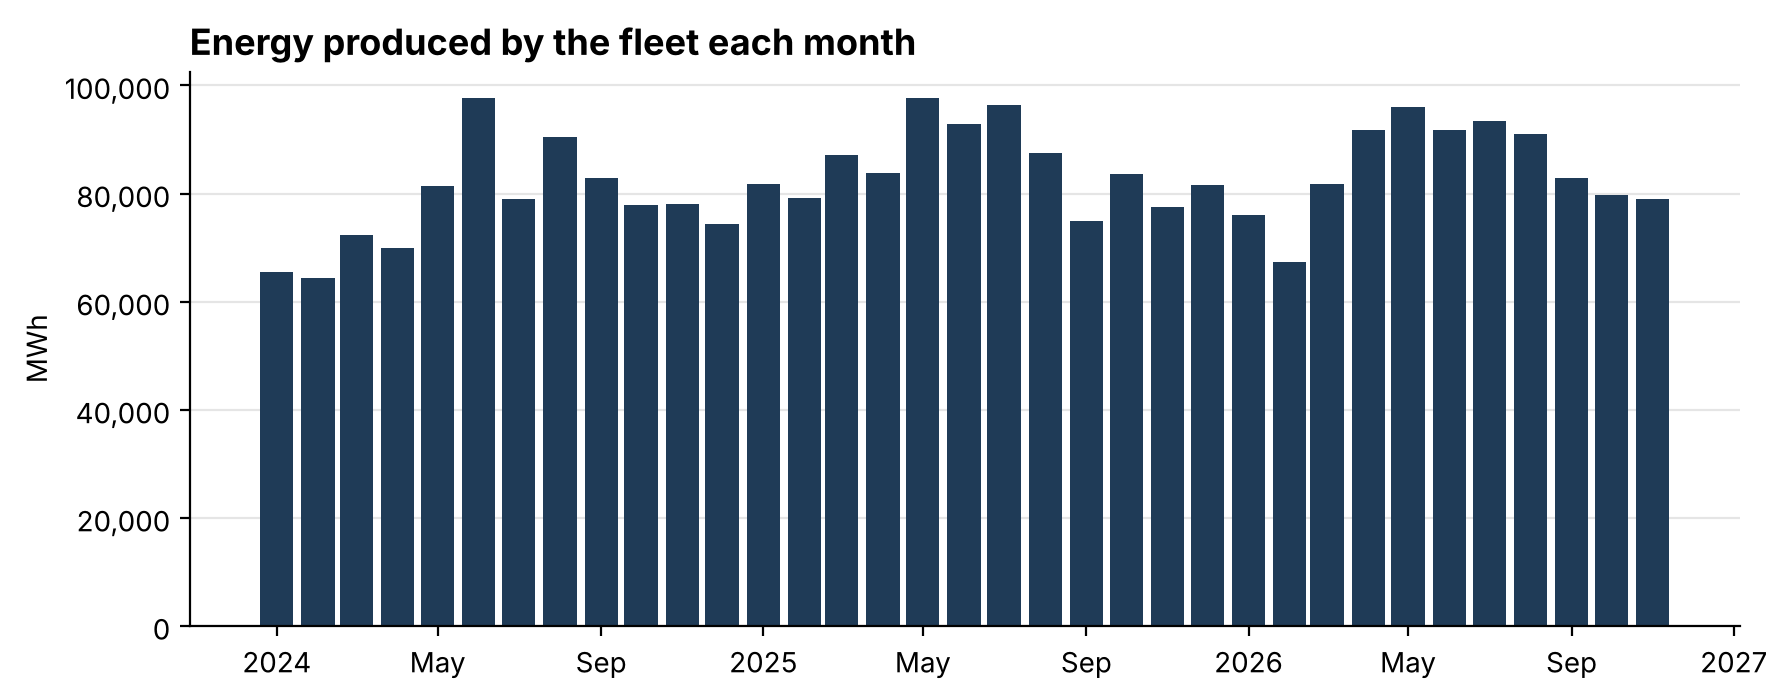

In [11]:
fleet_monthly = summarize_by(add_month(daily), ["month"])
events = alerts.downtime_events(daily, electricity_price=100)

plots.monthly_bars(fleet_monthly, "production_mwh", "Energy produced by the fleet each month", "MWh");

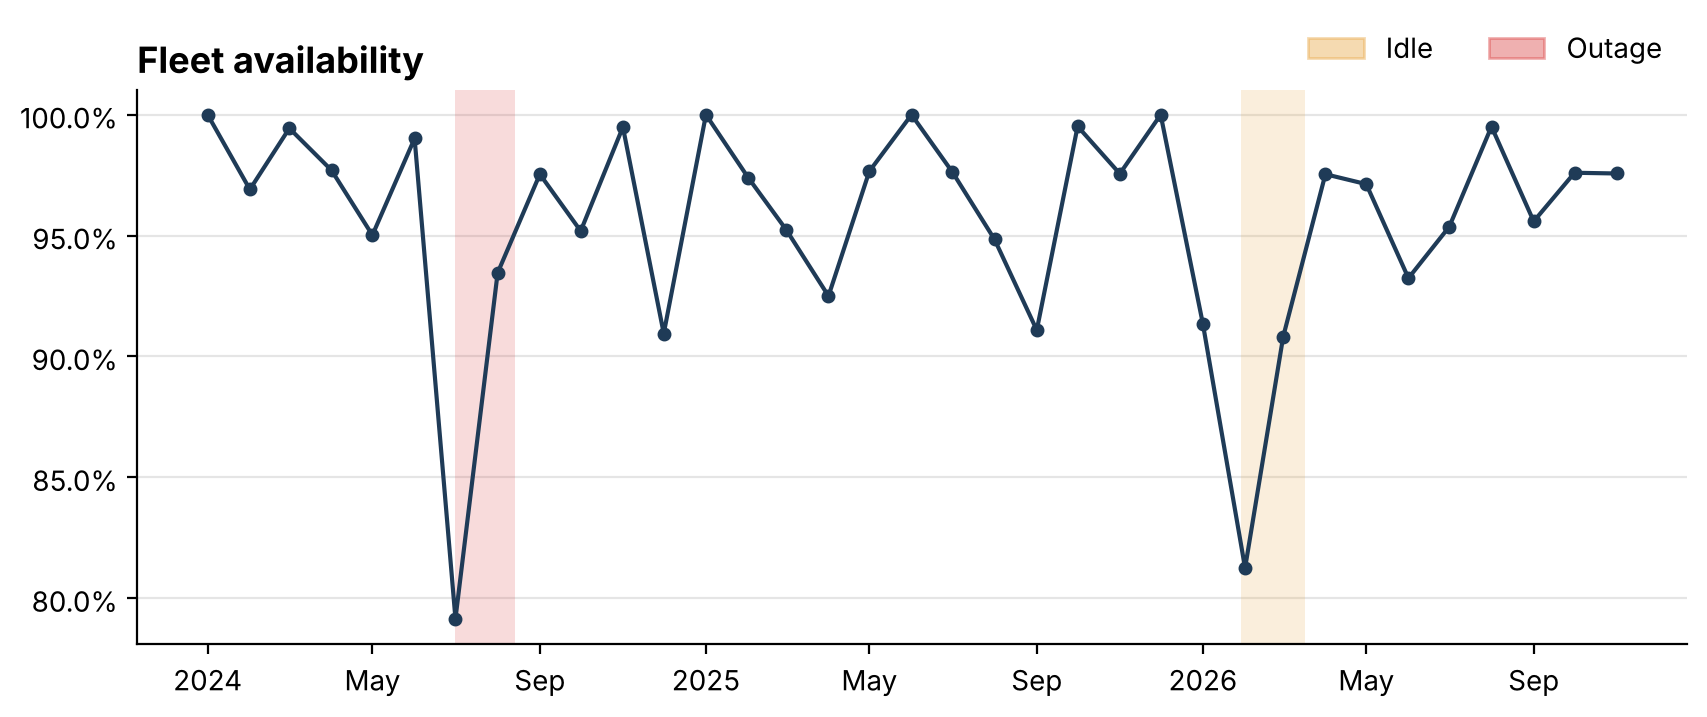

In [12]:
plots.monthly_line(fleet_monthly, "availability", "Fleet availability", events, percent=True);

The two dips in availability are the two scenarios. The heatmap shows which ship
caused them:

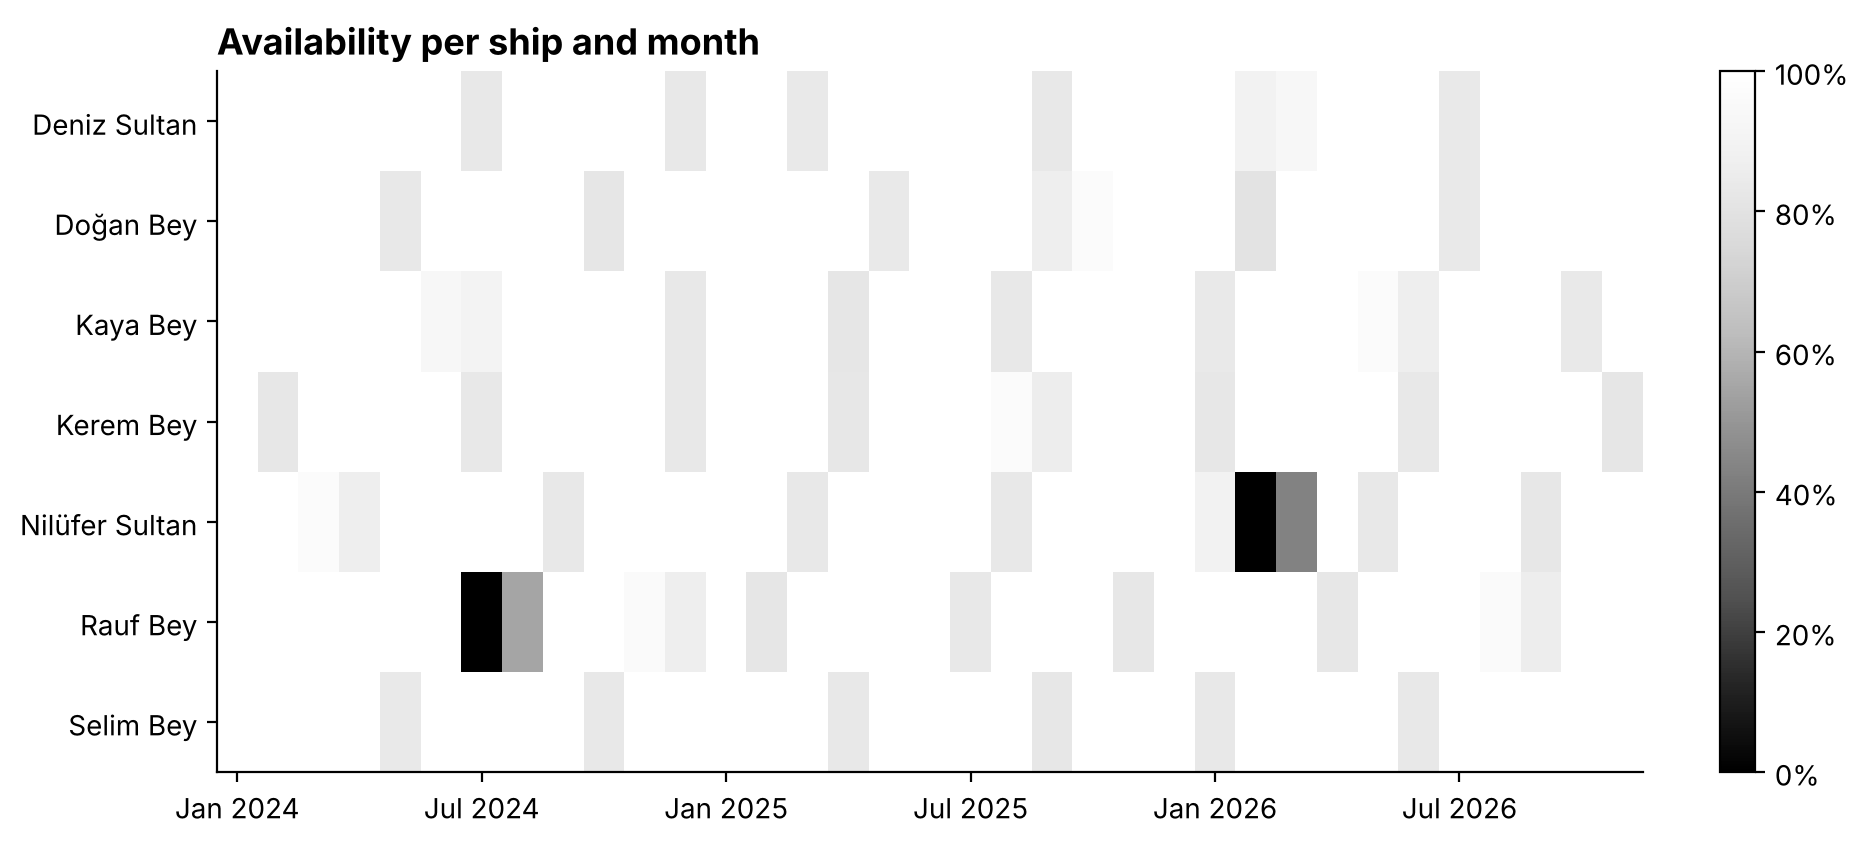

In [13]:
plots.availability_heatmap(availability);

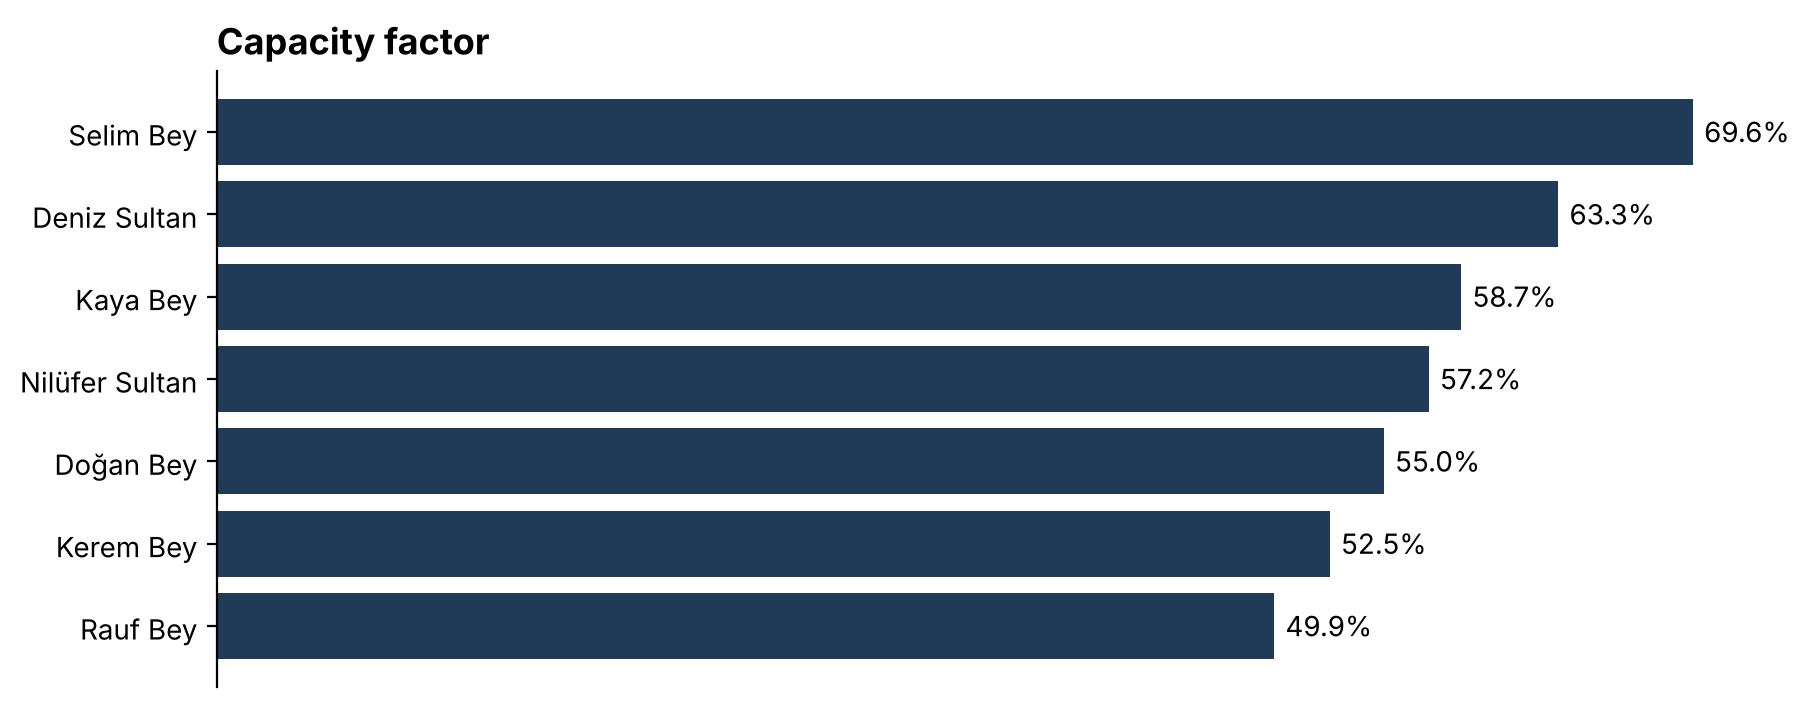

In [14]:
plots.ship_bars(summarize_by(daily, ["ship_name"]), "capacity_factor", "Capacity factor", "{:.1%}");

## 6. Downtime and efficiency alerts

`downtime_events` lists every period a ship was down. `efficiency_check`
compares each ship's last-7-days efficiency with its normal level (median of
the previous 60 days); `efficiency_alerts` groups the days that were more than
4 % below normal.

In [15]:
events[events["days"] >= 14]

,ship_name,type,start,end,days,cause,standby_fuel_t,lost_mwh,lost_revenue
5,Rauf Bey,Outage,2024-07-01,2024-08-14,45,Main engine crankshaft bearing failure,128.7,16295,1629450
33,Nilüfer Sultan,Idle,2026-01-29,2026-03-17,48,"Waiting offshore, no connection to the grid",37.4,16872,1687200


In [16]:
check = alerts.efficiency_check(daily)
alerts.efficiency_alerts(check, events)

,ship_name,from,to,days,worst_drop,followed_by,warning_days_before
0,Rauf Bey,2024-06-15,2024-06-30,14,-0.085109,Outage,16


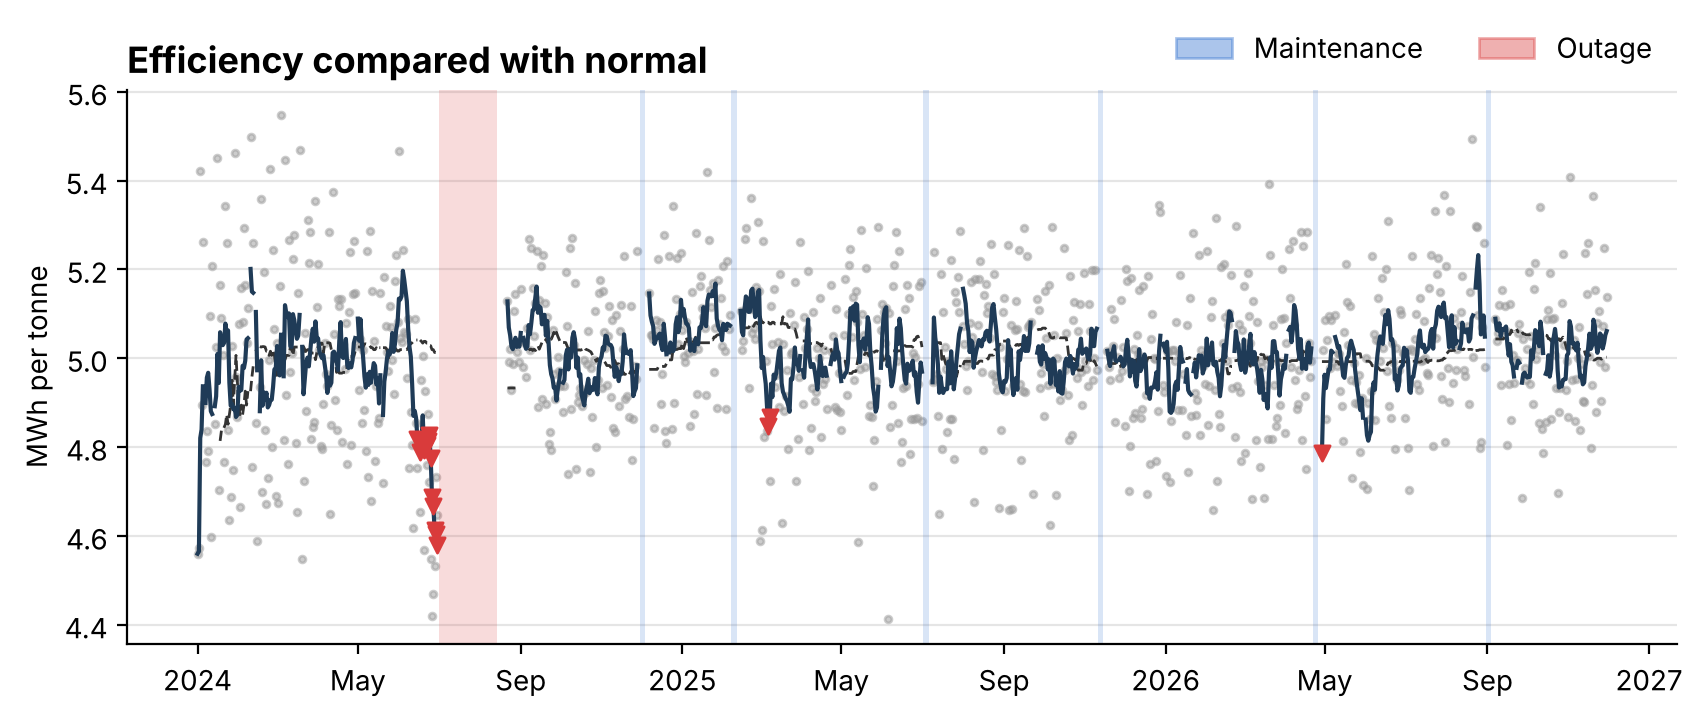

In [17]:
rauf = "Rauf Bey"
plots.efficiency_vs_normal(check[check["ship_name"] == rauf], events[events["ship_name"] == rauf]);

The efficiency of Rauf Bey started to drop more than two weeks before the
breakdown: an early warning the team could have acted on.

## 7. Statistics with numpy and scipy

**Efficiency of each ship** (mean, standard deviation, percentiles, variation):

In [18]:
analysis.efficiency_statistics(daily)

,ship_name,days,mean,std,p10,median,p90,variation_pct
0,Deniz Sultan,851,5.293,0.099,5.167,5.294,5.419,1.863
1,Doğan Bey,972,4.992,0.165,4.780,4.994,5.197,3.297
2,Kaya Bey,983,4.963,0.167,4.765,4.962,5.160,3.359
3,Kerem Bey,971,4.595,0.138,4.413,4.601,4.767,3.009
4,Nilüfer Sultan,939,5.049,0.102,4.916,5.047,5.171,2.014
5,Rauf Bey,933,5.007,0.171,4.795,5.012,5.230,3.416
6,Selim Bey,993,5.248,0.114,5.106,5.246,5.396,2.169


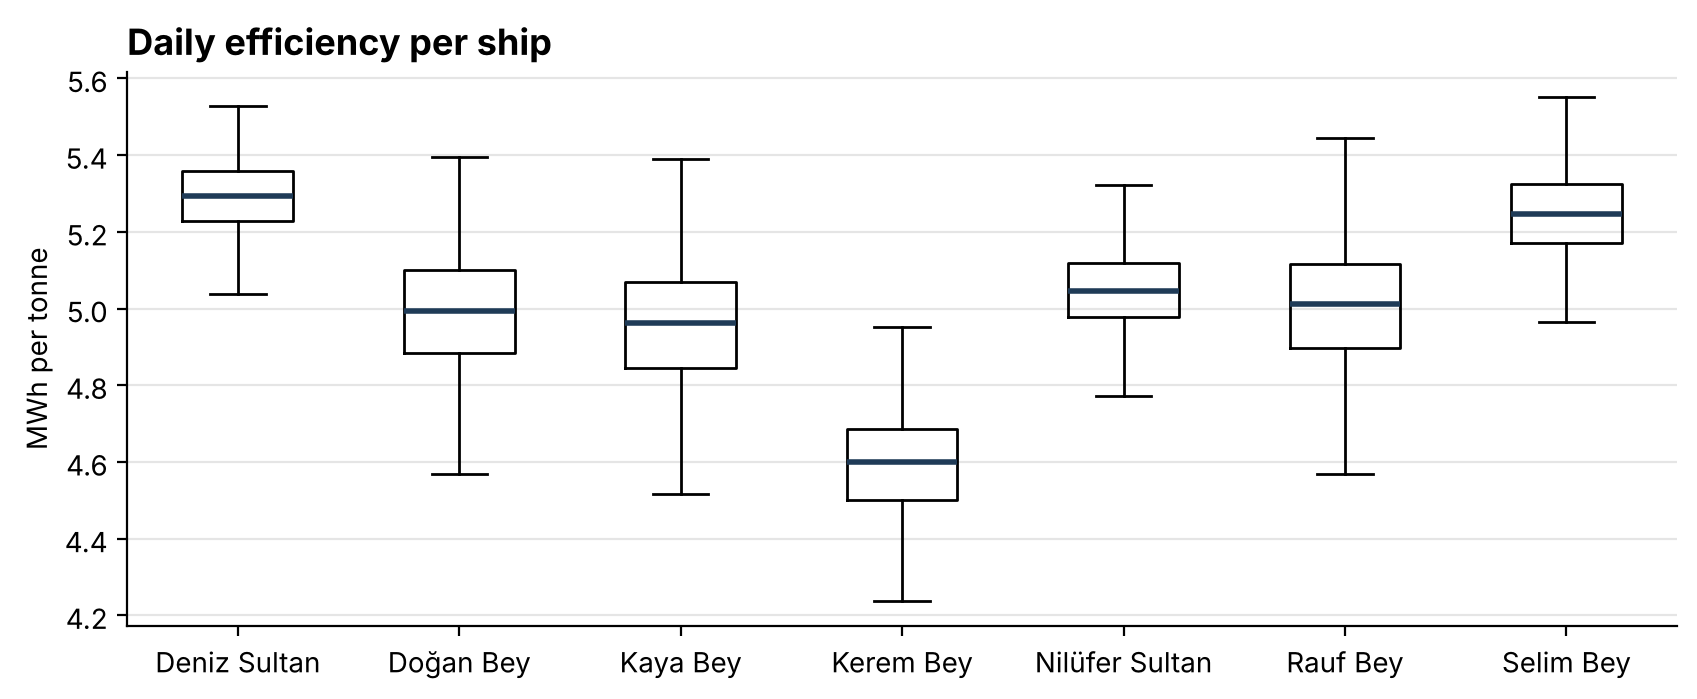

In [19]:
plots.efficiency_boxplot(daily);

**Seasonal pattern**: average capacity factor in each calendar month.

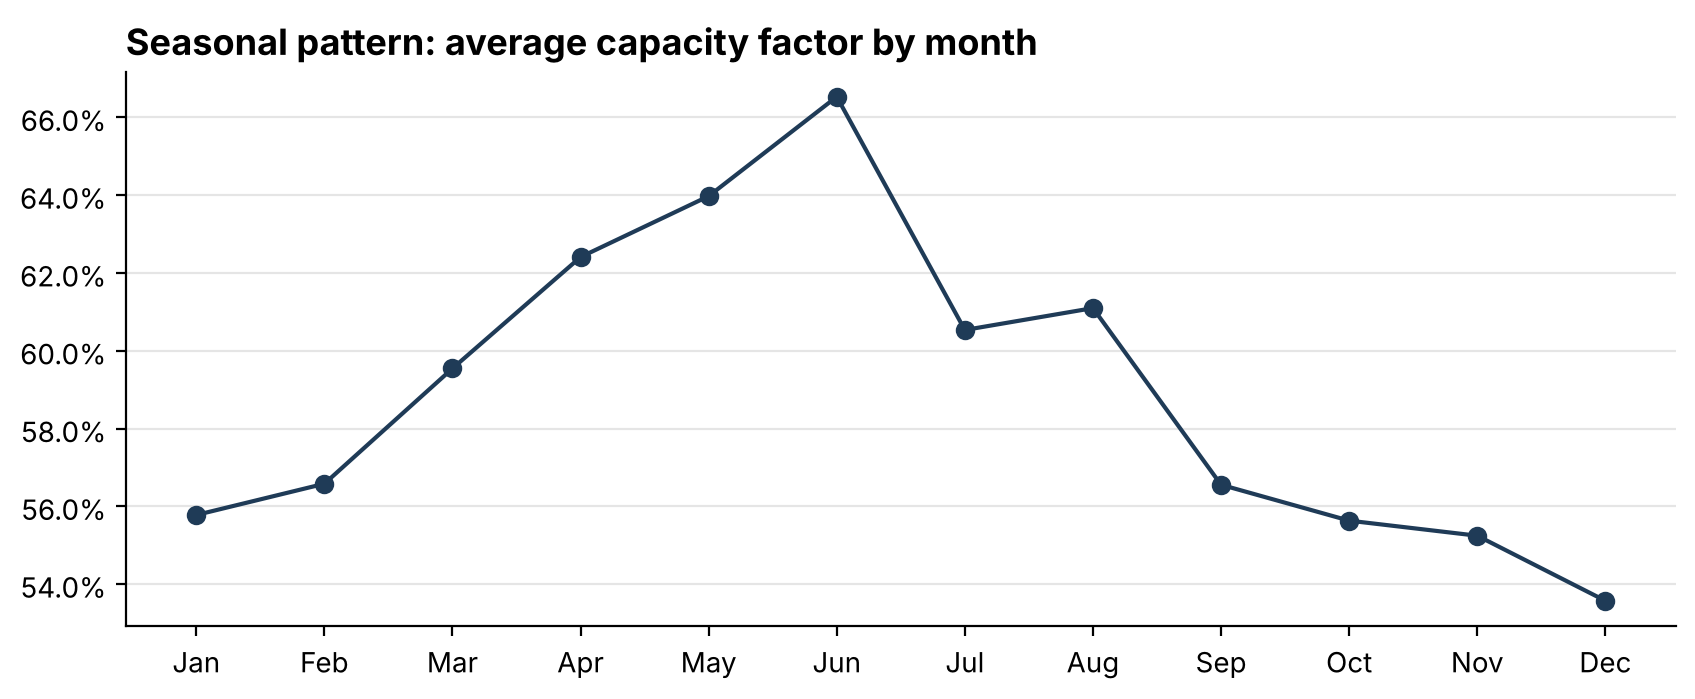

In [20]:
plots.seasonal_line(analysis.seasonal_profile(daily));

**Trend** (linear regression with `scipy.stats.linregress`): is efficiency
changing over time? A p-value below 0.05 means the trend is unlikely to be noise.

In [21]:
analysis.efficiency_trend(daily)

,ship_name,months,change_per_year,r_squared,p_value
0,Deniz Sultan,31,0.0018,0.0059,0.6812
1,Doğan Bey,35,0.0009,0.0008,0.8755
2,Kaya Bey,35,-0.0129,0.1269,0.0357
3,Kerem Bey,35,-0.0001,0.0000,0.9907
4,Nilüfer Sultan,34,0.0044,0.0396,0.2595
5,Rauf Bey,34,0.0100,0.0313,0.3172
6,Selim Bey,35,-0.0001,0.0000,0.9775


**Was there a warning before each long downtime?** (Welch t-test with
`scipy.stats.ttest_ind`): efficiency in the 3 weeks before the downtime compared
with the 2 months before that.

In [22]:
analysis.before_downtime_test(daily, events)

,ship_name,downtime,normal_mwh_per_ton,before_mwh_per_ton,change_pct,p_value,significant
0,Rauf Bey,Outage from 01 Jul 2024,5.0220,4.7404,-5.6071,0.0000,True
1,Nilüfer Sultan,Idle from 29 Jan 2026,5.0438,5.0789,0.6960,0.2727,False


## 8. Conclusions

- The fleet's availability is at least 90 % in 33 of the 35 months; the two big dips are the
  Rauf Bey breakdown (July 2024) and the Nilüfer Sultan idle period (February 2026).
- Rauf Bey's efficiency dropped by about 6 % in the three weeks before its breakdown,
  and the t-test shows the drop is statistically significant: monitoring efficiency
  gives an early warning of technical problems.
- Nilüfer Sultan shows **no** drop before its idle period: the cause was external
  (no connection to the grid), not the engines.
- Demand has a clear seasonal pattern, with a peak in late spring and summer.
- Kerem Bey is the least efficient ship (about 4.6 MWh/t), while Kaya Bey has the
  largest gap to its design efficiency (about -6 %) and the highest extra fuel cost:
  both are good candidates for an engine overhaul.